# Colab Üzerinde Veriyi İndirme

In [2]:
import kagglehub
import pandas as pd
import os
import shutil

# 1. Veriyi indir (Senin harika yöntemin!)
print("Veri indiriliyor...")
path = kagglehub.dataset_download("jenny18/honey-bee-annotated-images")
print("Kagglehub indirme dizini:", path)

# 2. Kaynak dosya yollarını belirle
csv_path = os.path.join(path, 'bee_data.csv')
source_imgs_dir = os.path.join(path, 'bee_imgs', 'bee_imgs')

# 3. Hedef dizini belirle (Colab'in ana dizininde görünür yapmak için)
base_dir = '/content/processed_data'

# 4. CSV'yi oku ve resimleri sınıflarına göre klasörle
print("PyTorch için klasörleme işlemi başlıyor...")
df = pd.read_csv(csv_path)

for index, row in df.iterrows():
    label = str(row['health']) # Etiketi al (Örn: 'Healthy', 'Varroa, Small Hive Beetles')
    img_name = str(row['file']) # Resim adını al (Örn: '041_066.png')

    # Sınıf klasörünü oluştur
    target_path = os.path.join(base_dir, label)
    os.makedirs(target_path, exist_ok=True)

    # Resmi orijinal yerinden alıp yeni klasörüne kopyala
    kaynak_resim = os.path.join(source_imgs_dir, img_name)
    hedef_resim = os.path.join(target_path, img_name)

    if os.path.exists(kaynak_resim):
        shutil.copy(kaynak_resim, hedef_resim)

print(f"İşlem tamam! Tüm veriler '{base_dir}' klasörü altında hazır.")

Veri indiriliyor...


100%|██████████| 50.5M/50.5M [00:00<00:00, 174MB/s]

Extracting files...


Kagglehub indirme dizini: /root/.cache/kagglehub/datasets/jenny18/honey-bee-annotated-images/versions/2
PyTorch için klasörleme işlemi başlıyor...
İşlem tamam! Tüm veriler '/content/processed_data' klasörü altında hazır.


## EDA

/tmp/ipykernel_12808/3237707329.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, y='health', order=df['health'].value_counts().index, palette='viridis')


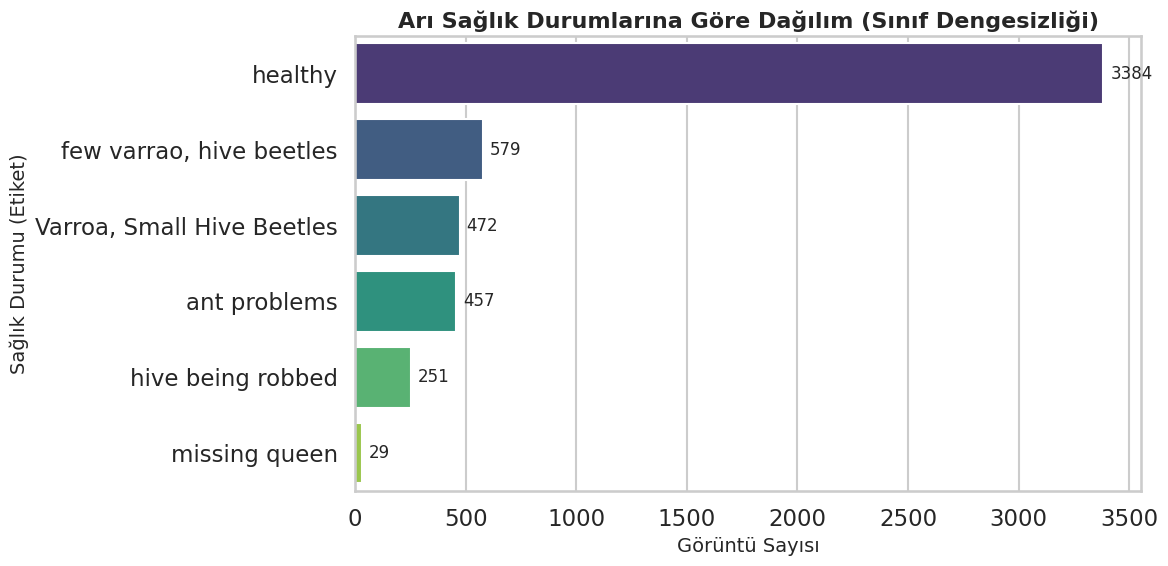

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.image as mpimg
import os
import random

# Grafiklerin arka planını ve stilini daha profesyonel ayarlayalım
sns.set_theme(style="whitegrid", context="talk")

# --- GRAFİK 1: Sınıf (Sağlık Durumu) Dağılımı ---
# Neden önemli? Jüriye sınıflar arasındaki dengesizliği (neden F1-Score/Recall kullandığınızı) kanıtlar.
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df, y='health', order=df['health'].value_counts().index, palette='viridis')
plt.title('Arı Sağlık Durumlarına Göre Dağılım (Sınıf Dengesizliği)', fontsize=16, fontweight='bold')
plt.xlabel('Görüntü Sayısı', fontsize=14)
plt.ylabel('Sağlık Durumu (Etiket)', fontsize=14)

# Barların yanına sayıları yazdırma
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}',
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=12)
plt.tight_layout()
plt.show()



/tmp/ipykernel_12808/2913761000.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, y='subspecies', order=df['subspecies'].value_counts().index, palette='magma')


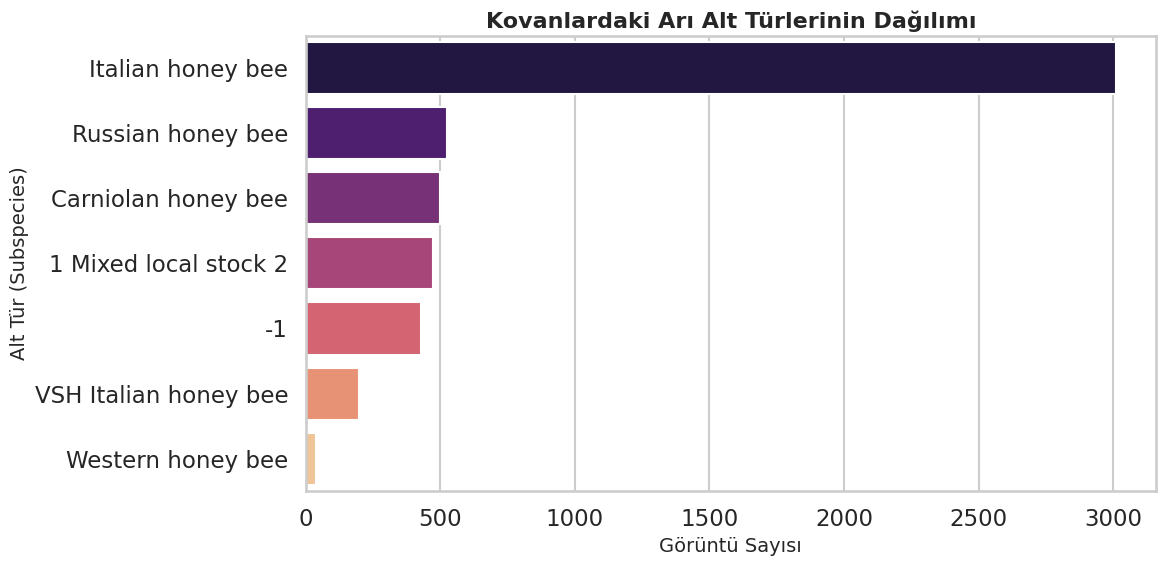

In [4]:
# --- GRAFİK 2: Arı Alt Türleri (Subspecies) Dağılımı ---
# Neden önemli? Veri setinin biyolojik çeşitliliğini gösterir.
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=df, y='subspecies', order=df['subspecies'].value_counts().index, palette='magma')
plt.title('Kovanlardaki Arı Alt Türlerinin Dağılımı', fontsize=16, fontweight='bold')
plt.xlabel('Görüntü Sayısı', fontsize=14)
plt.ylabel('Alt Tür (Subspecies)', fontsize=14)
plt.tight_layout()
plt.show()



/tmp/ipykernel_12808/3427187407.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, y='location', order=df['location'].value_counts().index, palette='cubehelix')


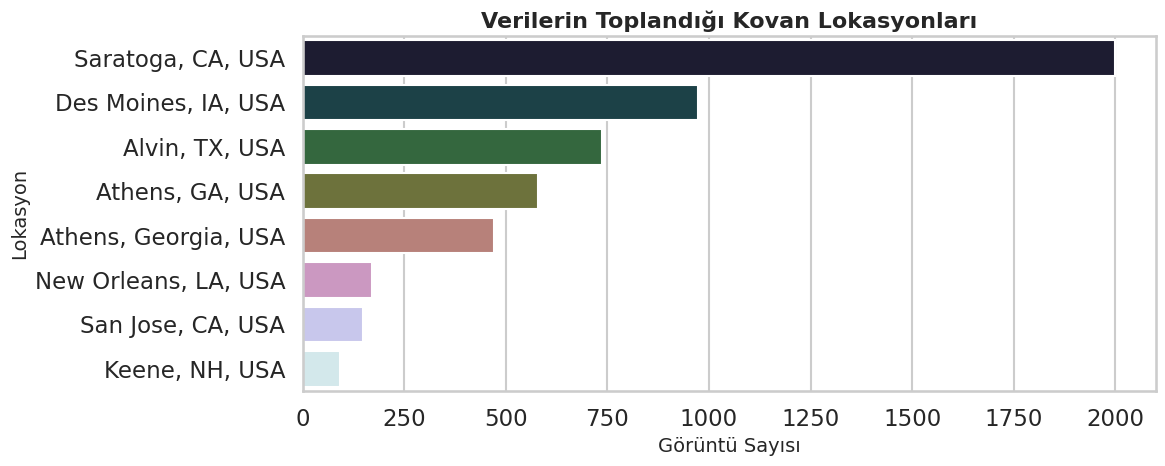

In [5]:
# --- GRAFİK 3: Lokasyon Dağılımı ---
# Neden önemli? Verilerin hangi bölgelerden (farklı kovanlardan) toplandığını gösterir, modelin genellenebilirliğini destekler.
plt.figure(figsize=(12, 5))
ax = sns.countplot(data=df, y='location', order=df['location'].value_counts().index, palette='cubehelix')
plt.title('Verilerin Toplandığı Kovan Lokasyonları', fontsize=16, fontweight='bold')
plt.xlabel('Görüntü Sayısı', fontsize=14)
plt.ylabel('Lokasyon', fontsize=14)
plt.tight_layout()
plt.show()



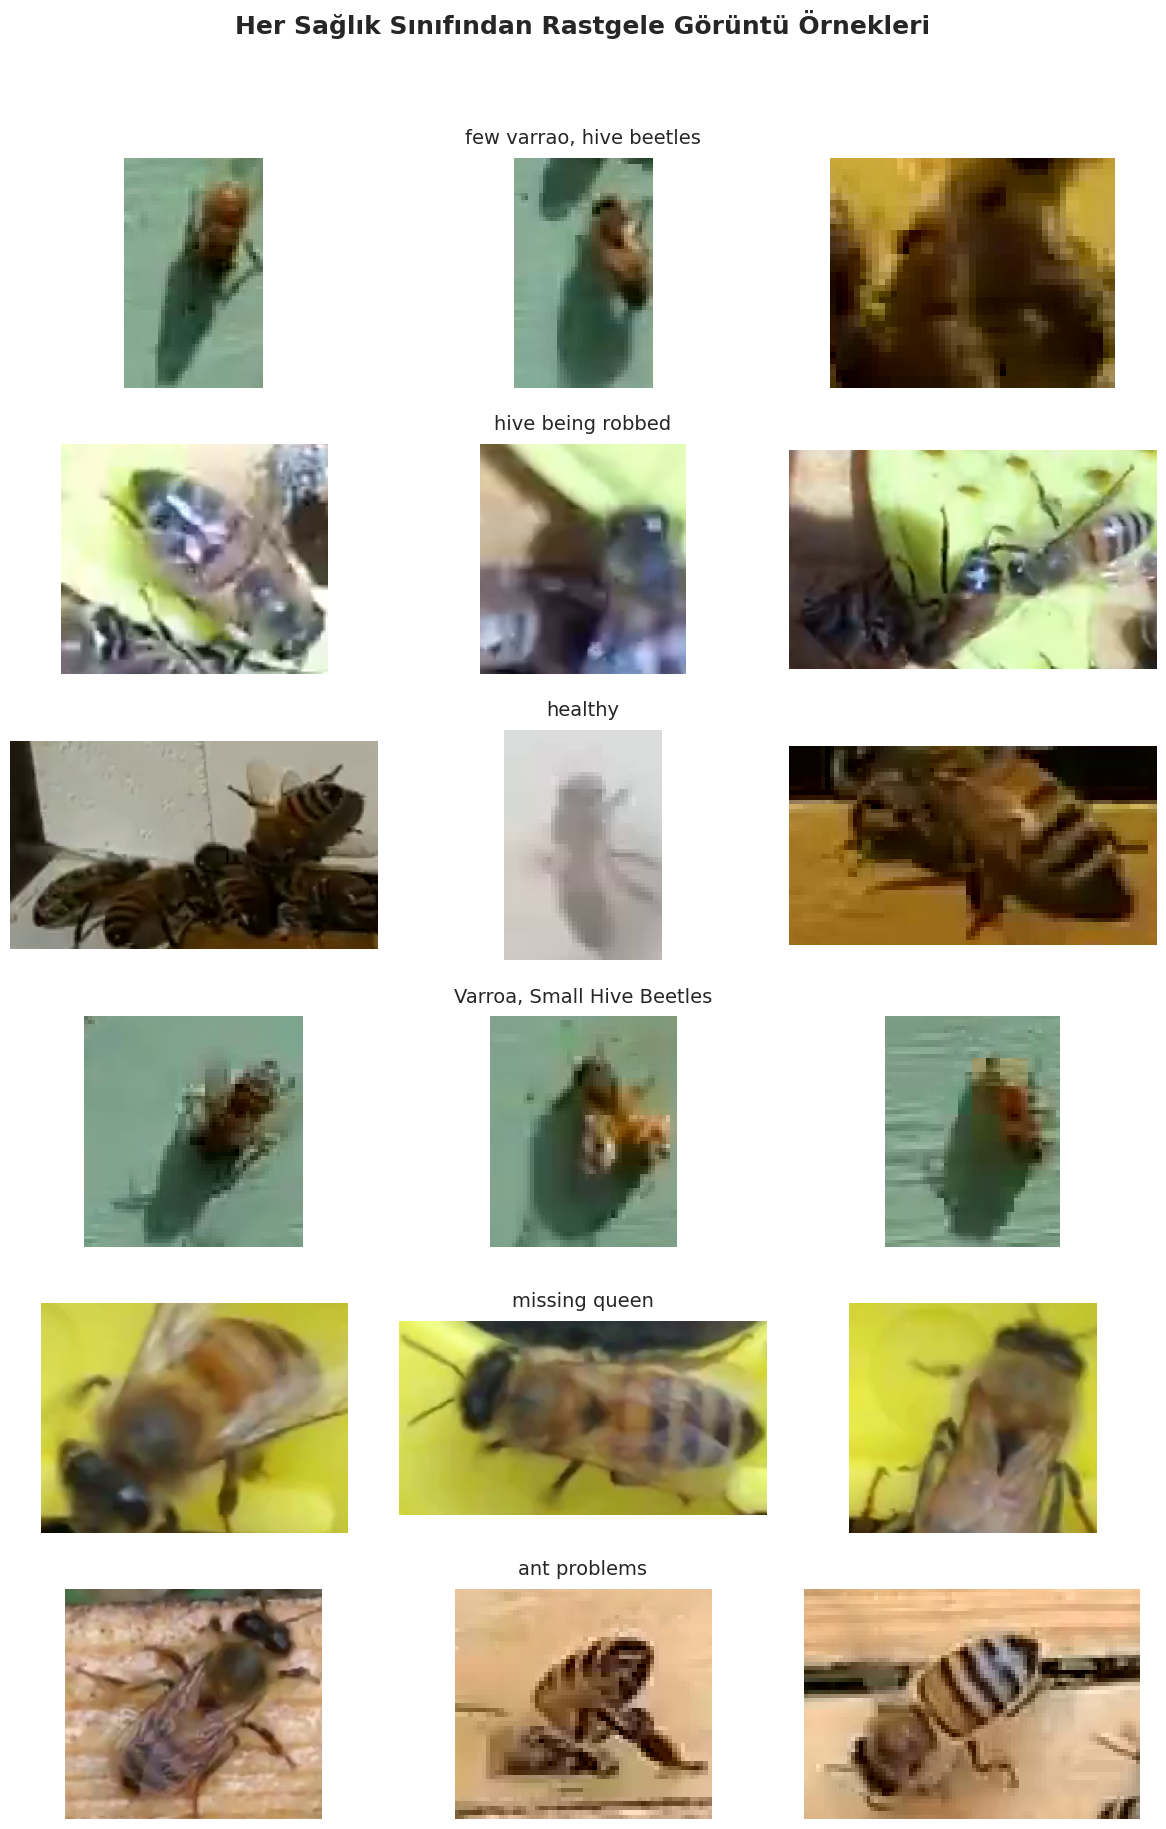

In [6]:
# --- GRAFİK 4: Her Sınıftan Rastgele Örnek Görüntüler (Görsel Matris) ---
# Neden önemli? Sunumda "Kameradan arılar nasıl görünüyor?" sorusunu doğrudan cevaplar.
base_dir = '/content/processed_data'
classes = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]

# Her sınıf için 3 örnek gösterecek şekilde bir matris (ızgara) oluşturuyoruz
num_classes = len(classes)
fig, axes = plt.subplots(num_classes, 3, figsize=(12, 3 * num_classes))
fig.suptitle('Her Sağlık Sınıfından Rastgele Görüntü Örnekleri', fontsize=18, fontweight='bold', y=1.02)

for i, cls in enumerate(classes):
    cls_path = os.path.join(base_dir, cls)
    images = os.listdir(cls_path)
    # Eğer o sınıfta 3'ten az resim varsa olanları al, yoksa 3 tane rastgele seç
    sample_imgs = random.sample(images, min(3, len(images)))

    for j, img_name in enumerate(sample_imgs):
        img_path = os.path.join(cls_path, img_name)
        img = mpimg.imread(img_path)

        # Eğer sadece 1 sınıf olsaydı axes 1 boyutlu olurdu, çoklu sınıfta 2 boyutlu
        ax = axes[i, j] if num_classes > 1 else axes[j]
        ax.imshow(img)
        ax.axis('off')
        if j == 1: # Ortadaki resmin üstüne sınıf adını yaz
            ax.set_title(cls, fontsize=14, pad=10)

plt.tight_layout()
plt.show()

# Hazırlık ve Ön-İşleme (Transforms)


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Ödev Maddesi 2: Sayısallaştırma ve Ön-işleme
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # Resizing
    transforms.ToTensor(),         # Normalization (0-1 aralığı)
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) # Standartlaştırma
])

# Klasörden veriyi yükle
full_dataset = datasets.ImageFolder(root='/content/processed_data', transform=data_transforms)
print(f"Toplam Görüntü Sayısı: {len(full_dataset)}")
print(f"Sınıflar: {full_dataset.classes}")

Toplam Görüntü Sayısı: 5172
Sınıflar: ['Varroa, Small Hive Beetles', 'ant problems', 'few varrao, hive beetles', 'healthy', 'hive being robbed', 'missing queen']



🔍 Modelin Eğitim Sırasında Göreceği (Ön-İşlemden Geçmiş) Görüntüler:


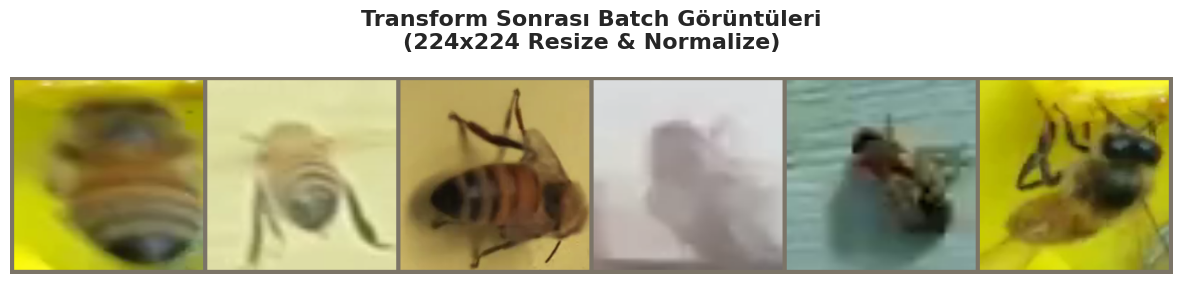

In [8]:
import matplotlib.pyplot as plt
import torchvision
import numpy as np
from torch.utils.data import DataLoader

# 1. Görselleştirme için küçük bir veri yükleyici (DataLoader) oluşturuyoruz
# batch_size=6 diyerek rastgele 6 resim çekeceğiz
vis_loader = DataLoader(full_dataset, batch_size=6, shuffle=True)

# 2. PyTorch Tensörlerini Matplotlib'in anlayacağı formata geri çeviren fonksiyon (Denormalizasyon)
def imshow_tensor(inp, title=None):
    """Normalize edilmiş PyTorch tensörünü geri çevirip ekrana çizer."""
    # Tensörü Numpy dizisine çevir ve boyutları ayarla (C, H, W -> H, W, C)
    inp = inp.numpy().transpose((1, 2, 0))

    # Kullandığın Normalizasyon değerlerini geri alıyoruz (Denormalization)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1) # Değerleri 0-1 aralığında tut

    plt.figure(figsize=(15, 5))
    plt.imshow(inp)
    if title is not None:
        plt.title(title, fontsize=16, fontweight='bold', pad=20)
    plt.axis('off')
    plt.show()

# 3. Veri yükleyiciden 1 tur (batch) veri çek
inputs, classes = next(iter(vis_loader))

# 4. Görüntüleri yan yana bir ızgara (grid) haline getir
out = torchvision.utils.make_grid(inputs, nrow=6, padding=5, normalize=False)

# 5. Sınıf isimlerini al
class_names = full_dataset.classes
title_str = " | ".join([class_names[x] for x in classes])

# 6. Ekrana Çizdir
print("\n🔍 Modelin Eğitim Sırasında Göreceği (Ön-İşlemden Geçmiş) Görüntüler:")
imshow_tensor(out, title="Transform Sonrası Batch Görüntüleri\n(224x224 Resize & Normalize)")


# Veri Ayrımı ve 10-Fold CV Kurulumu

In [9]:
# Ödev Maddesi 5: %70 Eğitim, %30 Test Ayrımı
targets = np.array(full_dataset.targets)
train_idx, test_idx = train_test_split(
    np.arange(len(targets)),
    test_size=0.30,
    stratify=targets,
    random_state=42
)

train_set = Subset(full_dataset, train_idx)
test_set = Subset(full_dataset, test_idx)

# Ödev Maddesi 6: 10-Fold Cross Validation
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
train_targets = targets[train_idx]

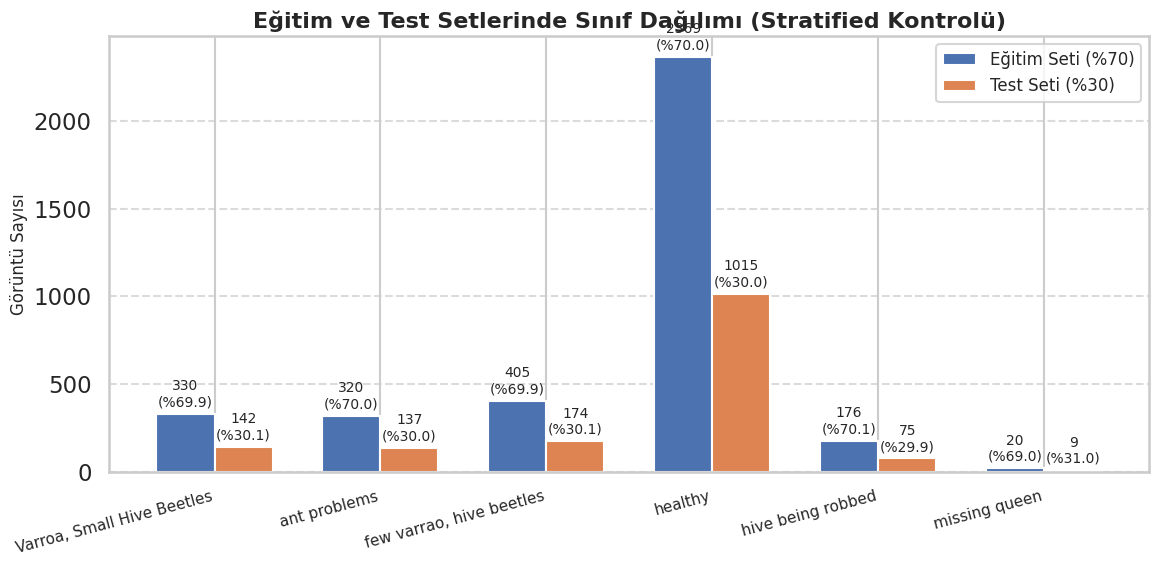

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Sınıf isimlerini ve Test etiketlerini alalım
class_names = full_dataset.classes
test_targets = targets[test_idx]

# Her sınıf için Eğitim ve Test setindeki veri sayılarını hesaplayalım
train_counts = [np.sum(train_targets == i) for i in range(len(class_names))]
test_counts = [np.sum(test_targets == i) for i in range(len(class_names))]

# Grafik Ayarları
x = np.arange(len(class_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

# Yan yana barları oluşturalım
rects1 = ax.bar(x - width/2, train_counts, width, label='Eğitim Seti (%70)', color='#4C72B0')
rects2 = ax.bar(x + width/2, test_counts, width, label='Test Seti (%30)', color='#DD8452')

# Eksenleri ve başlıkları ayarlayalım
ax.set_ylabel('Görüntü Sayısı', fontsize=12)
ax.set_title('Eğitim ve Test Setlerinde Sınıf Dağılımı (Stratified Kontrolü)', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=15, ha='right', fontsize=11)
ax.legend(fontsize=12)

# Arka plana hafif bir ızgara ekleyelim
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

# Barların üzerine tam sayıları ve yüzdelik dilimleri yazdıran fonksiyon
def autolabel(rects, total_counts):
    for rect, total in zip(rects, total_counts):
        height = rect.get_height()
        # O sınıfın toplamı içindeki yüzdesini hesapla
        percentage = (height / total) * 100 if total > 0 else 0

        ax.annotate(f'{int(height)}\n(%{percentage:.1f})',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 point dikey öteleme
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

# Sınıf bazında toplam sayıları hesapla (Eğitim + Test)
total_per_class = [tr + ts for tr, ts in zip(train_counts, test_counts)]

autolabel(rects1, total_per_class)
autolabel(rects2, total_per_class)

fig.tight_layout()
plt.show()

## Eğitim ve Değerlendirme Döngüsü

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Cihaz ayarı (Colab'de GPU açık değilse 'cpu' çalışır)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan Cihaz: {device}")

# Sonuçları tutacağımız listeler
knn_metrics = []
cnn_metrics = []

# Uyarı vermeyen metrik hesaplama fonksiyonumuz
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average='weighted', zero_division=0),
        "Recall": recall_score(y_true, y_pred, average='weighted', zero_division=0),
        "F1": f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

for fold, (cv_train_idx, cv_val_idx) in enumerate(skf.split(train_idx, train_targets)):
    print(f"\n=== Fold {fold+1}/10 Başlıyor ===")

    # DataLoader'ları hazırlama
    fold_train_sub = torch.utils.data.Subset(train_set, cv_train_idx)
    fold_val_sub = torch.utils.data.Subset(train_set, cv_val_idx)

    train_loader = torch.utils.data.DataLoader(fold_train_sub, batch_size=32, shuffle=True)
    val_loader = torch.utils.data.DataLoader(fold_val_sub, batch_size=32, shuffle=False)

    # ---------------------------------------------------------
    # ALGORİTMA 1: K-NN
    # ---------------------------------------------------------
    def get_flattened_data(loader):
        X_flat, y_flat = [], []
        for imgs, lbls in loader:
            X_flat.append(imgs.view(imgs.size(0), -1).numpy())
            y_flat.append(lbls.numpy())
        return np.vstack(X_flat), np.concatenate(y_flat)

    X_train_knn, y_train_knn = get_flattened_data(train_loader)
    X_val_knn, y_val_knn = get_flattened_data(val_loader)

    knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
    knn.fit(X_train_knn, y_train_knn)
    knn_preds = knn.predict(X_val_knn)

    knn_metrics.append(calculate_metrics(y_val_knn, knn_preds))

    # ---------------------------------------------------------
    # ALGORİTMA 2: CNN (MobileNetV2)
    # ---------------------------------------------------------
    # PyTorch'un yeni standartlarına göre model yükleme
    model_cnn = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    model_cnn.classifier[1] = nn.Linear(model_cnn.last_channel, len(full_dataset.classes))
    model_cnn = model_cnn.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model_cnn.parameters(), lr=0.001)

    # CNN için 1 Epoch'luk Hızlı Eğitim Döngüsü (Süreyi kısaltmak için)
    model_cnn.train()
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_cnn(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    # CNN Değerlendirme Döngüsü
    model_cnn.eval()
    cnn_preds, cnn_targets = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            outputs = model_cnn(inputs)
            _, predicted = torch.max(outputs.data, 1)
            cnn_preds.extend(predicted.cpu().numpy())
            cnn_targets.extend(labels.numpy())

    cnn_metrics.append(calculate_metrics(cnn_targets, cnn_preds))
    print(f"Fold {fold+1} tamamlandı.")

# ---------------------------------------------------------
# FİNAL RAPORU (10 Fold'un Ortalaması)
# ---------------------------------------------------------
print("\n" + "="*40)
print("🎯 10-FOLD CROSS VALIDATION SONUÇLARI")
print("="*40)

def print_average_metrics(metrics_list, model_name):
    avg_acc = np.mean([m["Accuracy"] for m in metrics_list])
    avg_prec = np.mean([m["Precision"] for m in metrics_list])
    avg_rec = np.mean([m["Recall"] for m in metrics_list])
    avg_f1 = np.mean([m["F1"] for m in metrics_list])

    print(f"\n{model_name} Ortalama Performansı:")
    print(f"Accuracy : {avg_acc:.4f}")
    print(f"Precision: {avg_prec:.4f}")
    print(f"Recall   : {avg_rec:.4f}")
    print(f"F1-Score : {avg_f1:.4f}")

print_average_metrics(knn_metrics, "Algoritma-1: K-NN (Euclidean)")
print_average_metrics(cnn_metrics, "Algoritma-2: CNN (MobileNetV2)")

Kullanılan Cihaz: cuda

=== Fold 1/10 Başlıyor ===
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 145MB/s]


Fold 1 tamamlandı.

=== Fold 2/10 Başlıyor ===
Fold 2 tamamlandı.

=== Fold 3/10 Başlıyor ===
Fold 3 tamamlandı.

=== Fold 4/10 Başlıyor ===
Fold 4 tamamlandı.

=== Fold 5/10 Başlıyor ===
Fold 5 tamamlandı.

=== Fold 6/10 Başlıyor ===
Fold 6 tamamlandı.

=== Fold 7/10 Başlıyor ===
Fold 7 tamamlandı.

=== Fold 8/10 Başlıyor ===
Fold 8 tamamlandı.

=== Fold 9/10 Başlıyor ===
Fold 9 tamamlandı.

=== Fold 10/10 Başlıyor ===
Fold 10 tamamlandı.

🎯 10-FOLD CROSS VALIDATION SONUÇLARI

Algoritma-1: K-NN (Euclidean) Ortalama Performansı:
Accuracy : 0.8356
Precision: 0.8407
Recall   : 0.8356
F1-Score : 0.8206

Algoritma-2: CNN (MobileNetV2) Ortalama Performansı:
Accuracy : 0.9403
Precision: 0.9449
Recall   : 0.9403
F1-Score : 0.9379


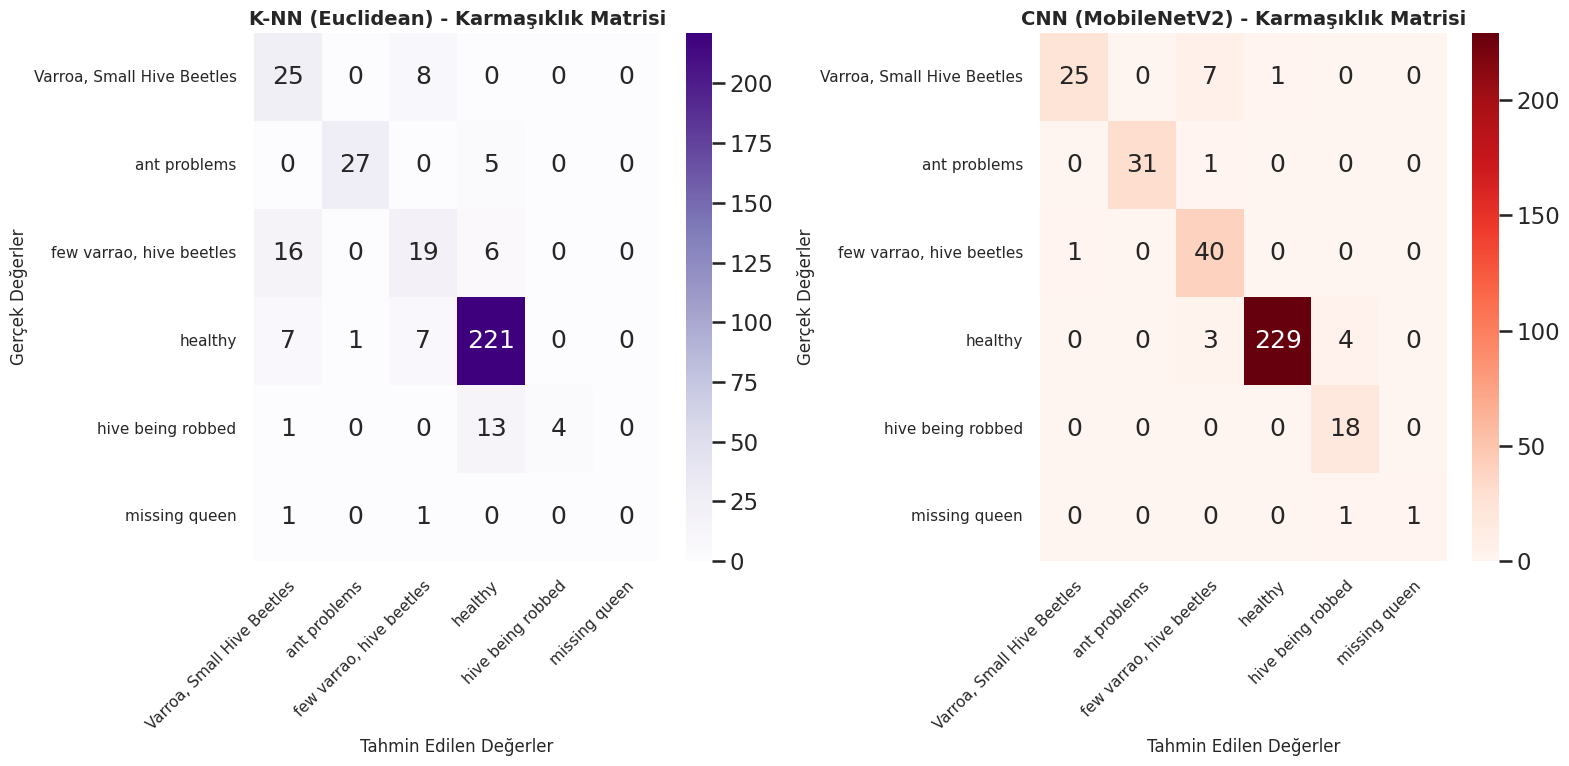

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Sınıf isimlerini alalım
class_names = full_dataset.classes

# Son Fold'un (Fold 10) KNN ve CNN tahminleri ile Karmaşıklık Matrislerini hesapla
cm_knn = confusion_matrix(y_val_knn, knn_preds)
cm_cnn = confusion_matrix(cnn_targets, cnn_preds)

# Grafiğin boyunu biraz uzattık (figsize=(16, 8) yaptık) ki yazılara yer kalsın
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# K-NN Matrisi
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title('K-NN (Euclidean) - Karmaşıklık Matrisi', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Gerçek Değerler', fontsize=12)
axes[0].set_xlabel('Tahmin Edilen Değerler', fontsize=12)

# CNN Matrisi
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('CNN (MobileNetV2) - Karmaşıklık Matrisi', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Gerçek Değerler', fontsize=12)
axes[1].set_xlabel('Tahmin Edilen Değerler', fontsize=12)

# YAZILARIN BİRBİRİNE GİRMESİNİ ENGELLEYEN KRİTİK DÜZELTME
for ax in axes:
    # Hem 45 derece döndürüyoruz, hem de 'ha="right"' ile kelimenin sonundan hizalıyoruz
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=11)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=11)

# Grafikleri pencereye tam sığdır
plt.tight_layout()
plt.show()

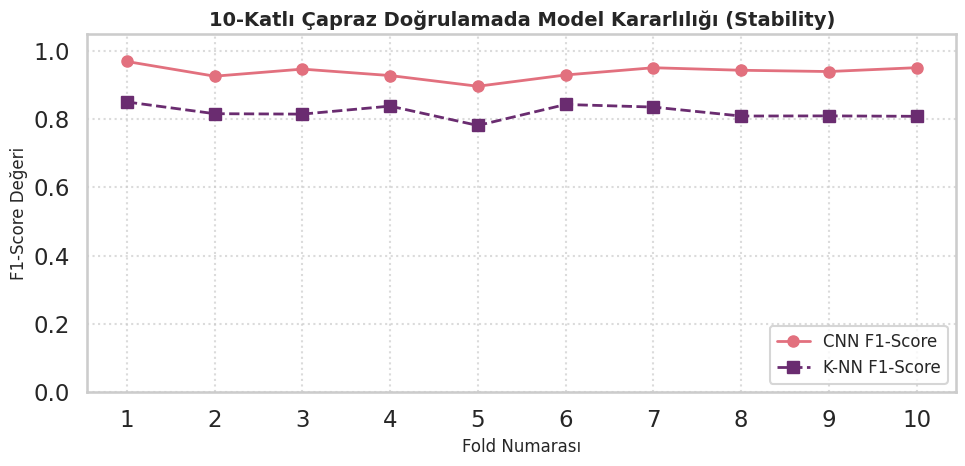

In [13]:
# 1'den 10'a kadar Fold numaraları
folds = np.arange(1, 11)

# Listelerden sadece F1-Score ve Accuracy değerlerini çekelim
cnn_f1 = [m['F1'] for m in cnn_metrics]
knn_f1 = [m['F1'] for m in knn_metrics]

plt.figure(figsize=(10, 5))

# Çizgileri ve veri noktalarını (marker) çizelim
plt.plot(folds, cnn_f1, marker='o', linestyle='-', linewidth=2, color='#e2707e', label='CNN F1-Score', markersize=8)
plt.plot(folds, knn_f1, marker='s', linestyle='--', linewidth=2, color='#6a2c70', label='K-NN F1-Score', markersize=8)

plt.title('10-Katlı Çapraz Doğrulamada Model Kararlılığı (Stability)', fontsize=14, fontweight='bold')
plt.xlabel('Fold Numarası', fontsize=12)
plt.ylabel('F1-Score Değeri', fontsize=12)
plt.xticks(folds) # X ekseninde 1,2..10 tam sayıları görünsün
plt.ylim(0.0, 1.05)
plt.legend(loc='lower right', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

Son doğrulama setinde CNN toplam 18 adet hata yaptı.


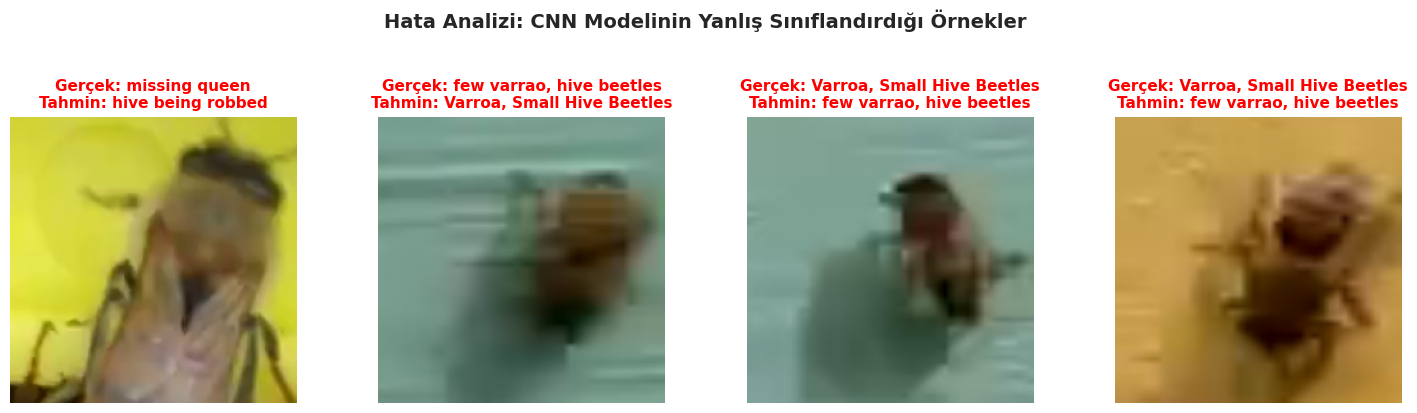

In [14]:
import torchvision

# CNN'in tahminleri ile gerçek etiketlerin eşleşmediği (hata yaptığı) indeksleri bul
cnn_preds_np = np.array(cnn_preds)
cnn_targets_np = np.array(cnn_targets)
error_indices = np.where(cnn_preds_np != cnn_targets_np)[0]

print(f"Son doğrulama setinde CNN toplam {len(error_indices)} adet hata yaptı.")

if len(error_indices) > 0:
    # Göstermek için en fazla 4 hata seçelim
    num_to_show = min(4, len(error_indices))
    sample_errors = error_indices[:num_to_show]

    fig, axes = plt.subplots(1, num_to_show, figsize=(15, 4))
    if num_to_show == 1: axes = [axes] # Tek hata varsa array yapısını korumak için

    # Denormalizasyon fonksiyonumuz (Önceki adımdan)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # Son val_loader'dan resimleri tekrar çekmek için listeye dönüştürelim
    val_images = []
    for imgs, lbls in val_loader:
        val_images.extend(imgs)

    for i, idx in enumerate(sample_errors):
        img_tensor = val_images[idx]

        # Tensörü resme çevir (Denormalize)
        img_np = img_tensor.numpy().transpose((1, 2, 0))
        img_np = std * img_np + mean
        img_np = np.clip(img_np, 0, 1)

        gercek_sinif = class_names[cnn_targets_np[idx]]
        tahmin_sinif = class_names[cnn_preds_np[idx]]

        axes[i].imshow(img_np)
        axes[i].set_title(f"Gerçek: {gercek_sinif}\nTahmin: {tahmin_sinif}",
                          color='red', fontsize=11, fontweight='bold')
        axes[i].axis('off')

    plt.suptitle('Hata Analizi: CNN Modelinin Yanlış Sınıflandırdığı Örnekler', fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

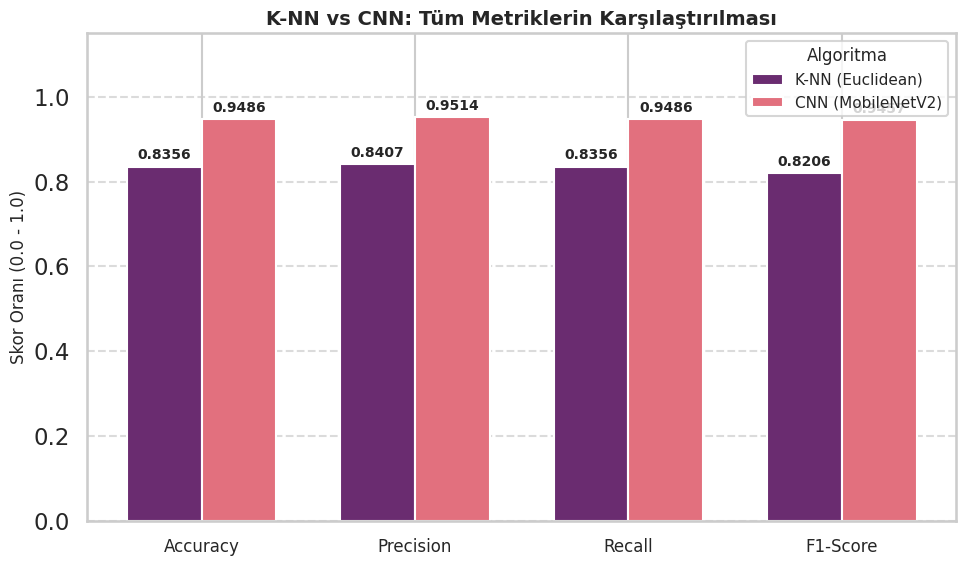

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# 10-Fold CV Ortalama Sonuçlarımız
metrikler = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
knn_skorlar = [0.8356, 0.8407, 0.8356, 0.8206]
cnn_skorlar = [0.9486, 0.9514, 0.9486, 0.9457]

# X ekseni konumları ve bar genişliği
x = np.arange(len(metrikler))
width = 0.35

# Grafik boyutunu ayarlama
fig, ax = plt.subplots(figsize=(10, 6))

# Barları çizme (Mor ve Pembe/Kırmızı tonları)
rects1 = ax.bar(x - width/2, knn_skorlar, width, label='K-NN (Euclidean)', color='#6a2c70')
rects2 = ax.bar(x + width/2, cnn_skorlar, width, label='CNN (MobileNetV2)', color='#e2707e')

# Eksen yazıları ve Başlık
ax.set_ylabel('Skor Oranı (0.0 - 1.0)', fontsize=12)
ax.set_title('K-NN vs CNN: Tüm Metriklerin Karşılaştırılması', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrikler, fontsize=12)
ax.set_ylim(0, 1.15) # Değerlerin barın üstüne sığması için yüksekliği artırdık
ax.legend(title='Algoritma', fontsize=11, title_fontsize=12)

# Arka plan ızgarası (Grid)
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

# Barların tepesine tam değerleri yazdıran fonksiyon
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 point yukarı
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()